In [10]:
import numpy as np
import ifcopenshell
import heapq
import matplotlib.pyplot as plt

# for some reason ifcopenshell.api is not imported when importing ifcopenshell, so we need to import it explicitly
import ifcopenshell.api.root
import ifcopenshell.api.unit
import ifcopenshell.api.context
import ifcopenshell.api.project
import ifcopenshell.api.geometry

model = ifcopenshell.open("Function_Model_hospital.ifc")

# defined as a dictionary, because there can be multiple boundaries related by openings
def get_boundary_room(space):
    b_room = {}
    for boundary in space.BoundedBy:
        corr_boundary = boundary.CorrespondingBoundary
        b_room[boundary.RelatedBuildingElement.Name] = corr_boundary.RelatingSpace
    return b_room

def get_openings(space):
    openings = {}
    for boundary in space.BoundedBy:
        if boundary.RelatedBuildingElement.is_a("IfcOpeningElement"):
            openings[boundary.RelatedBuildingElement.Name] = boundary.RelatedBuildingElement
    return openings

def get_coordinates(entity):
    matrix = ifcopenshell.util.placement.get_local_placement(entity.ObjectPlacement)
    return matrix[:,3][0:3]

###### other functions to add later:
# get length/width of a space
# calculate distance between spaces




Do the edge weightings need to be known before implementing the algorithm?
Probably not, but
since I'm finding the worst case from a given building, there is no "start". So I guess will need to iterate through every path anyway?


In [11]:
import networkx as nx
import plotly.graph_objects as go

def build_nx_space_graph(model):
    """Build a graph of IfcSpaces connected through IfcOpeningElements."""
    G = nx.Graph()

    for space in model.by_type("IfcSpace"):
        s1 = space.Name or f"IfcSpace_{space.id()}"
        G.add_node(s1, ifc_id=space.id())

        for b in getattr(space, "BoundedBy", []):
            if not b.is_a("IfcRelSpaceBoundary2ndLevel"):
                continue

            cb = getattr(b, "CorrespondingBoundary", None)
            if not cb:
                continue

            elem = getattr(b, "RelatedBuildingElement", None)
            if not elem or not elem.is_a("IfcOpeningElement"):
                continue

            s2_obj = cb.RelatingSpace
            s2 = s2_obj.Name or f"IfcSpace_{s2_obj.id()}"
            opening_name = elem.Name or f"IfcOpeningElement_{elem.id()}"

            if not G.has_edge(s1, s2):
                G.add_edge(
                    s1,
                    s2,
                    opening=opening_name,
                    opening_id=elem.id(),
                    boundary_id=b.id(),
                    corresponding_boundary_id=cb.id(),
                )

    return G

G = build_nx_space_graph(model)

In [12]:
# Keep the relationship spaces and boundary spaces separate.
graph_space_by_node = {
    space.Name or f"IfcSpace_{space.id()}": space
    for space in model.by_type("IfcSpace")
    if not getattr(space, "BoundedBy", [])
}

boundary_space_by_node = {
    space.Name or f"IfcSpace_{space.id()}": space
    for space in model.by_type("IfcSpace")
    if getattr(space, "BoundedBy", [])
}

In [13]:
import heapq
import networkx as nx
import ifcopenshell.geom
from shapely.geometry import MultiPoint

# Map graph nodes to the duplicate spaces containing boundary relationships.
space_by_node = boundary_space_by_node


def node_coordinates(node):
    """Return the x, y coordinates for a graph node."""
    return get_coordinates(space_by_node[node])[:2]


geometry_settings = ifcopenshell.geom.settings()


def get_space_wall_footprints(node):
    """Return 2D wall footprints forming the space boundary."""
    space = space_by_node[node]
    walls = []

    for boundary in getattr(space, "BoundedBy", []):
        wall = getattr(boundary, "RelatedBuildingElement", None)
        if wall is not None and wall.is_a("IfcWall"):
            walls.append(wall)

    if not walls:
        wall_prefix = f"{node}wall".lower()
        walls = [
            wall
            for wall in model.by_type("IfcWall")
            if (wall.Name or "").lower().startswith(wall_prefix)
        ]

    wall_footprints = []
    for wall in walls:
        try:
            shape = ifcopenshell.geom.create_shape(geometry_settings, wall)
        except RuntimeError:
            continue

        vertices = np.asarray(shape.geometry.verts).reshape(-1, 3)
        transform = np.asarray(shape.transformation.matrix).reshape(4, 4)
        homogeneous_vertices = np.column_stack(
            (vertices, np.ones(len(vertices)))
        )
        world_vertices = (homogeneous_vertices @ transform)[:, :3]
        footprint = MultiPoint(world_vertices[:, :2]).convex_hull
        if not footprint.is_empty:
            wall_footprints.append(footprint)

    return wall_footprints


def furthest_coordinates_from_opening(node, opening):
    """Return the wall point farthest from the edge opening."""
    opening_coordinates = get_coordinates(opening)[:2]
    wall_footprints = get_space_wall_footprints(node)

    if wall_footprints:
        candidate_points = np.vstack([
            np.asarray(footprint.exterior.coords)
            for footprint in wall_footprints
        ])
        distances = np.linalg.norm(
            candidate_points - opening_coordinates,
            axis=1,
        )
        return candidate_points[np.argmax(distances)]

    space_coordinates = node_coordinates(node)
    direction_away_from_opening = space_coordinates - opening_coordinates
    return space_coordinates + direction_away_from_opening


def edge_cost(graph, current, neighbor, start=None, entry_opening=None):
    """Measure from the current position to the next opening."""
    opening_id = graph.edges[current, neighbor].get("opening_id")
    if opening_id is None:
        return float(np.linalg.norm(
            node_coordinates(current) - node_coordinates(neighbor)
        ))

    opening = model.by_id(opening_id)
    if current == start:
        current_coordinates = furthest_coordinates_from_opening(
            current,
            opening,
        )
    elif entry_opening is not None:
        current_coordinates = get_coordinates(entry_opening)[:2]
    else:
        current_coordinates = node_coordinates(current)

    return float(np.linalg.norm(
        current_coordinates - get_coordinates(opening)[:2]
    ))


def final_exit_cost(graph, previous, goal, exit_opening_name=None):
    """Return the distance across the goal space to its exit opening."""
    entering_opening_id = graph.edges[previous, goal].get("opening_id")

    if exit_opening_name is not None:
        exit_openings = [
            opening
            for opening in model.by_type("IfcOpeningElement")
            if opening.Name == exit_opening_name
        ]
    else:
        goal_space = space_by_node[goal]
        goal_openings = [
            boundary.RelatedBuildingElement
            for boundary in getattr(goal_space, "BoundedBy", [])
            if (
                boundary.is_a("IfcRelSpaceBoundary2ndLevel")
                and getattr(boundary, "RelatedBuildingElement", None)
                and boundary.RelatedBuildingElement.is_a("IfcOpeningElement")
            )
        ]
        exit_openings = [
            opening
            for opening in goal_openings
            if opening.id() != entering_opening_id
        ]

    if len(exit_openings) != 1:
        raise ValueError(
            f"Expected one exit opening for {goal!r}; "
            "pass exit_opening_name to a_star when it is not a second "
            "opening in the goal space"
        )

    entering_coordinates = get_coordinates(
        model.by_id(entering_opening_id)
    )[:2]
    exit_coordinates = get_coordinates(exit_openings[0])[:2]
    return float(np.linalg.norm(entering_coordinates - exit_coordinates))


def h_n(current, goal):
    """Euclidean heuristic."""
    return float(np.linalg.norm(
        node_coordinates(current) - node_coordinates(goal)
    ))


def a_star(graph, start, goal, exit_opening_name=None):
    """Find the shortest path and include the goal-room exit distance."""
    if start not in graph:
        raise ValueError(f"Unknown start node: {start}")

    if goal not in graph:
        raise ValueError(f"Unknown goal node: {goal}")

    open_set = [(h_n(start, goal), 0.0, start)]
    g_score = {start: 0.0}
    came_from = {}

    while open_set:
        _, current_cost, current = heapq.heappop(open_set)

        if current_cost > g_score.get(current, float("inf")):
            continue

        if current == goal:
            path = [current]
            while current in came_from:
                current = came_from[current]
                path.append(current)

            path.reverse()
            distance = g_score[goal]
            if len(path) > 1:
                distance += final_exit_cost(
                    graph,
                    path[-2],
                    goal,
                    exit_opening_name=exit_opening_name,
                )
            return path, distance

        entry_opening = None
        if current != start and current in came_from:
            previous = came_from[current]
            entry_opening_id = graph.edges[previous, current].get("opening_id")
            if entry_opening_id is not None:
                entry_opening = model.by_id(entry_opening_id)

        for neighbor in graph.neighbors(current):
            cost = edge_cost(
                graph,
                current,
                neighbor,
                start=start,
                entry_opening=entry_opening,
            )
            tentative_g_score = g_score[current] + cost

            if tentative_g_score < g_score.get(neighbor, float("inf")):
                came_from[neighbor] = current
                g_score[neighbor] = tentative_g_score
                f_score = tentative_g_score + h_n(neighbor, goal)
                heapq.heappush(
                    open_set,
                    (f_score, tentative_g_score, neighbor)
                )

    raise nx.NetworkXNoPath(
        f"No path exists between {start!r} and {goal!r}"
    )

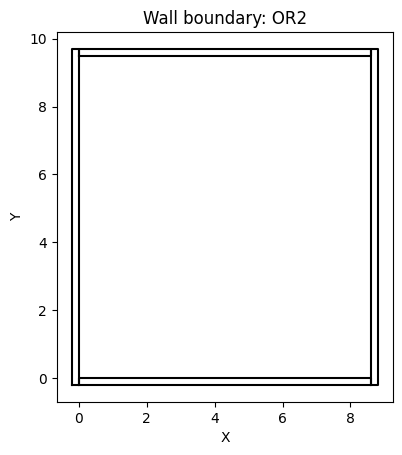

In [14]:
def draw_space_wall_boundary(node):
    """Draw the 2D footprints of walls bounding a space."""
    fig, axis = plt.subplots()

    for footprint in get_space_wall_footprints(node):
        x_values, y_values = footprint.exterior.xy
        axis.plot(x_values, y_values, "k-")

    axis.set_aspect("equal")
    axis.set_title(f"Wall boundary: {node}")
    axis.set_xlabel("X")
    axis.set_ylabel("Y")
    plt.show()


draw_space_wall_boundary("OR2")

In [15]:
# start = list(G.nodes)[0]
# start = "entry_lobby"
goal1 = "Northwest" # exit name = "north_exit"
goal2 = "Star2_Exit" # exit name = "south_exit"
goal3 = "Stair3_Exit" # exit name = "west_exit"
# note: the goal is currently set to the lobby, but it should be set to the exit door of these rooms


for room in list(G.nodes):
    print("Room:", room)
    path, distance = a_star(G, room, "Stair_Circ", exit_opening_name="Stair1_Exit")

    print("Path:", path)
    print("Distance:", distance)

# print("Room:", start)
# path, distance = a_star(G, start, goal1, exit_opening_name="north_exit")
# print("Path:", path)
# print("Distance:", distance)


# for room in list(G.nodes):
#     path, distance = a_star(G, room, goal2)

#     # print("Path:", path)
#     print("Distance:", distance)

# for room in list(G.nodes):
#     path, distance = a_star(G, room, goal3)

#     # print("Path:", path)
#     print("Distance:", distance)

Room: OR2
Path: ['OR2', 'ExB2', 'SW_Circ', 'NW_Circ', 'Stair_Circ']
Distance: 48.68234098354837
Room: AB2
Path: ['AB2', 'SW_Circ', 'NW_Circ', 'Stair_Circ']
Distance: 42.038742034124084
Room: ExB2
Path: ['ExB2', 'SW_Circ', 'NW_Circ', 'Stair_Circ']
Distance: 39.80823086196392
Room: Setup1
Path: ['Setup1', 'Set_Corr', 'SW_Circ', 'NW_Circ', 'Stair_Circ']
Distance: 42.944715773313334
Room: SW_Circ
Path: ['SW_Circ', 'NW_Circ', 'Stair_Circ']
Distance: 38.50776168468647
Room: OR1
Path: ['OR1', 'AB1', 'SW_Circ', 'NW_Circ', 'Stair_Circ']
Distance: 34.71697268925075
Room: Set_Corr
Path: ['Set_Corr', 'SW_Circ', 'NW_Circ', 'Stair_Circ']
Distance: 33.997426496477004
Room: ExB1
Path: ['ExB1', 'SW_Circ', 'NW_Circ', 'Stair_Circ']
Distance: 28.170874345697566
Room: AB1
Path: ['AB1', 'SW_Circ', 'NW_Circ', 'Stair_Circ']
Distance: 25.134102955020605
Room: Store1
Path: ['Store1', 'SW_Circ', 'NW_Circ', 'Stair_Circ']
Distance: 30.88207419014774
Room: NW_Circ
Path: ['NW_Circ', 'Stair_Circ']
Distance: 45.817888

['OR2', 'AB2', 'ExB2', 'Setup1', 'SW_Circ', 'OR1', 'Set_Corr', 'ExB1', 'AB1', 'Store1', 'NW_Circ', 'ST_Stock', 'ExB3', 'AB3', 'IT1', 'Cath_Lab', 'Scrub1', 'Hyb_Theatre', 'Ctrl1', 'Med1', 'Lab1', 'SE_Circ', 'CPU2', 'Store2', 'CPU1', 'Travel1', 'Disp1', 'Clean2', 'ST_Equip1', 'Off1', 'Off2', 'AmenitiesF', 'AmenitiesM', 'LiftLobby1', 'LiftLobby2', 'WC', 'Lift_Circ', 'NE_Circ', 'Wait', 'Travel2', 'Int1', 'Int2', 'Int3', 'Int4', 'Cons1', 'Copy1', 'Change_Corr', 'Lounge', 'RecBay_Circ3', 'ST_Gen', 'Meet1', 'Stair_Circ', 'StaffR', 'ExB4', 'AnBay1', 'Setup2', 'BayCirc1', 'ST_Equip2', 'ST_Equip3', 'Bay_Res', 'OR3', 'Clean1', 'Dirty1', 'RecBay_Circ1', 'Clean3', 'Dirty2', 'RecBay_Circ2', 'ACC1', 'Plant']


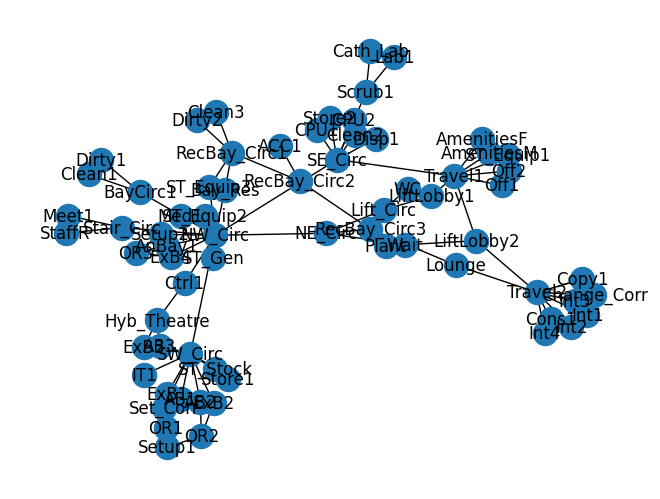

In [16]:
print(G.nodes)

goal = list(G.nodes)[-1]

# print(goal)

# use this to visualise/debug the graph
nx.draw(G, with_labels=True)
plt.show()

In [18]:
route_start = path[0]
print("Selected path:", path)
for index in range(len(path) - 1):
    current = path[index]
    neighbor = path[index + 1]
    entry_opening = None
    if index > 0:
        previous = path[index - 1]
        entry_opening_id = G.edges[previous, current]["opening_id"]
        entry_opening = model.by_id(entry_opening_id)
    print(
        current,
        "->",
        neighbor,
        edge_cost(
            G,
            current,
            neighbor,
            start=route_start,
            entry_opening=entry_opening,
        ),
    )

Selected path: ['Plant', 'RecBay_Circ3', 'NE_Circ', 'NW_Circ', 'Stair_Circ']
Plant -> RecBay_Circ3 11.933147112141041
RecBay_Circ3 -> NE_Circ 20.024984394500787
NE_Circ -> NW_Circ 25.0031997952262
NW_Circ -> Stair_Circ 40.77670903837141


Putting it all together for the current model...

In [25]:
# For each room, calculate A* to each goal, then store the shortest cost (i.e. either goal1, goal2, or goal3)
# then identify the 3 longest travel distance cases



# start = list(G.nodes)[0]
# start = "entry_lobby"
goal1 = "Stair_Circ" # exit name = "north_exit"
goal2 = "RecBay_Circ2" # exit name = "south_exit"
goal3 = "Wait" # exit name = "west_exit"
# note: the goal is currently set to the lobby, but it should be set to the exit door of these rooms

goal = [goal1, goal2, goal3]
exit_names = {
    goal1: "Stair1_Exit",
    goal2: "Stair2_Exit",
    goal3: "Stair3_Exit"
}

# the point of this is to store an array of the 3 longest travel distances, which are saved as dictionaries with the room, goal, distance and travel path
largest_travel_goal1 = []
largest_travel_goal2 = []
largest_travel_goal3 = []

for exit_goal in goal:

    print("-----------------------------------\n GOAL= ", exit_goal, "\n-----------------------------------")

    for room in list(G.nodes):
        print("Room", room)
        path, distance = a_star(G, room, exit_goal, exit_opening_name=exit_names[exit_goal])

        print("Path:", path)
        print("Distance: %.2f" % distance, "m\n")

        if exit_goal == goal1:
            if len(largest_travel_goal1) < 3:
                travel_path = {
                    "room": room,
                    "goal": exit_goal,
                    "distance": distance
                }
                largest_travel_goal1.append(travel_path)
                largest_travel_goal1 = sorted(largest_travel_goal1, key=lambda x: x["distance"], reverse=True)
            else:
                if distance > largest_travel_goal1[-1]["distance"]:
                    travel_path = {
                        "room": room,
                        "goal": exit_goal,
                        "path": path,
                        "distance": distance
                    }
                    largest_travel_goal1[-1] = travel_path
                    largest_travel_goal1 = sorted(largest_travel_goal1, key=lambda x: x["distance"], reverse=True)

        elif exit_goal == goal2:
            if len(largest_travel_goal2) < 3:
                travel_path = {
                    "room": room,
                    "goal": exit_goal,
                    "distance": distance
                }
                largest_travel_goal2.append(travel_path)
                largest_travel_goal2 = sorted(largest_travel_goal2, key=lambda x: x["distance"], reverse=True)
            else:
                if distance > largest_travel_goal2[-1]["distance"]:
                    travel_path = {
                        "room": room,
                        "goal": exit_goal,
                        "path": path,
                        "distance": distance
                    }
                    largest_travel_goal2[-1] = travel_path
                    largest_travel_goal2 = sorted(largest_travel_goal2, key=lambda x: x["distance"], reverse=True)
                    
        elif exit_goal == goal3:
            if len(largest_travel_goal3) < 3:
                travel_path = {
                    "room": room,
                    "goal": exit_goal,
                    "distance": distance
                }
                largest_travel_goal3.append(travel_path)
                largest_travel_goal3 = sorted(largest_travel_goal3, key=lambda x: x["distance"], reverse=True)
            else:
                if distance > largest_travel_goal3[-1]["distance"]:
                    travel_path = {
                        "room": room,
                        "goal": exit_goal,
                        "path": path,
                        "distance": distance
                    }
                    largest_travel_goal3[-1] = travel_path
                    largest_travel_goal3 = sorted(largest_travel_goal3, key=lambda x: x["distance"], reverse=True)

# note that there is a slight inaccuracy, when the starting room is the same as the goal room, the distance is calculated as 0.
# it should really be the distance from the furthest point of the room to the exit, but this case is not interesting for the egress analysis, so is not being rectified.


-----------------------------------
 GOAL=  Stair_Circ 
-----------------------------------
Room OR2
Path: ['OR2', 'ExB2', 'SW_Circ', 'NW_Circ', 'Stair_Circ']
Distance: 48.68 m

Room AB2
Path: ['AB2', 'SW_Circ', 'NW_Circ', 'Stair_Circ']
Distance: 42.04 m

Room ExB2
Path: ['ExB2', 'SW_Circ', 'NW_Circ', 'Stair_Circ']
Distance: 39.81 m

Room Setup1
Path: ['Setup1', 'Set_Corr', 'SW_Circ', 'NW_Circ', 'Stair_Circ']
Distance: 42.94 m

Room SW_Circ
Path: ['SW_Circ', 'NW_Circ', 'Stair_Circ']
Distance: 38.51 m

Room OR1
Path: ['OR1', 'AB1', 'SW_Circ', 'NW_Circ', 'Stair_Circ']
Distance: 34.72 m

Room Set_Corr
Path: ['Set_Corr', 'SW_Circ', 'NW_Circ', 'Stair_Circ']
Distance: 34.00 m

Room ExB1
Path: ['ExB1', 'SW_Circ', 'NW_Circ', 'Stair_Circ']
Distance: 28.17 m

Room AB1
Path: ['AB1', 'SW_Circ', 'NW_Circ', 'Stair_Circ']
Distance: 25.13 m

Room Store1
Path: ['Store1', 'SW_Circ', 'NW_Circ', 'Stair_Circ']
Distance: 30.88 m

Room NW_Circ
Path: ['NW_Circ', 'Stair_Circ']
Distance: 45.82 m

Room ST_Stock


In [26]:
# the details of the 3 longest travel distances from the algorithm can be printed as follows
for i in range(len(largest_travel_goal1)):
    print(largest_travel_goal1[i])

for i in range(len(largest_travel_goal2)):
    print(largest_travel_goal2[i])

for i in range(len(largest_travel_goal3)):
    print(largest_travel_goal3[i])


{'room': 'Plant', 'goal': 'Stair_Circ', 'path': ['Plant', 'RecBay_Circ3', 'NE_Circ', 'NW_Circ', 'Stair_Circ'], 'distance': 102.73804034023944}
{'room': 'RecBay_Circ2', 'goal': 'Stair_Circ', 'path': ['RecBay_Circ2', 'RecBay_Circ1', 'Bay_Res', 'NW_Circ', 'Stair_Circ'], 'distance': 95.91879828016712}
{'room': 'AmenitiesM', 'goal': 'Stair_Circ', 'path': ['AmenitiesM', 'Travel1', 'LiftLobby2', 'Wait', 'NE_Circ', 'NW_Circ', 'Stair_Circ'], 'distance': 94.03257559790734}
{'room': 'OR2', 'goal': 'RecBay_Circ2', 'distance': 113.78203996506709}
{'room': 'Setup1', 'goal': 'RecBay_Circ2', 'path': ['Setup1', 'Set_Corr', 'SW_Circ', 'NW_Circ', 'NE_Circ', 'RecBay_Circ3', 'RecBay_Circ2'], 'distance': 108.04441475483203}
{'room': 'AB2', 'goal': 'RecBay_Circ2', 'distance': 107.13844101564278}
{'room': 'OR2', 'goal': 'Wait', 'distance': 82.09082877501628}
{'room': 'Setup1', 'goal': 'Wait', 'path': ['Setup1', 'Set_Corr', 'SW_Circ', 'NW_Circ', 'NE_Circ', 'Wait'], 'distance': 76.35320356478123}
{'room': 'AB2'

In [42]:
degree_list = nx.degree(G)
sorted_degree_list = sorted(degree_list, key=lambda x: x[1], reverse=True)
sorted_degree_list

[('NW_Circ', 14),
 ('SW_Circ', 11),
 ('Travel2', 9),
 ('SE_Circ', 8),
 ('Travel1', 8),
 ('RecBay_Circ1', 5),
 ('NE_Circ', 4),
 ('RecBay_Circ3', 4),
 ('OR2', 3),
 ('Setup1', 3),
 ('OR1', 3),
 ('Scrub1', 3),
 ('Hyb_Theatre', 3),
 ('LiftLobby2', 3),
 ('Lift_Circ', 3),
 ('Stair_Circ', 3),
 ('BayCirc1', 3),
 ('OR3', 3),
 ('RecBay_Circ2', 3),
 ('AB2', 2),
 ('ExB2', 2),
 ('Set_Corr', 2),
 ('ExB1', 2),
 ('AB1', 2),
 ('ExB3', 2),
 ('AB3', 2),
 ('Ctrl1', 2),
 ('LiftLobby1', 2),
 ('Wait', 2),
 ('Lounge', 2),
 ('ExB4', 2),
 ('AnBay1', 2),
 ('Setup2', 2),
 ('ST_Equip3', 2),
 ('Bay_Res', 2),
 ('Store1', 1),
 ('ST_Stock', 1),
 ('IT1', 1),
 ('Cath_Lab', 1),
 ('Med1', 1),
 ('Lab1', 1),
 ('CPU2', 1),
 ('Store2', 1),
 ('CPU1', 1),
 ('Disp1', 1),
 ('Clean2', 1),
 ('ST_Equip1', 1),
 ('Off1', 1),
 ('Off2', 1),
 ('AmenitiesF', 1),
 ('AmenitiesM', 1),
 ('WC', 1),
 ('Int1', 1),
 ('Int2', 1),
 ('Int3', 1),
 ('Int4', 1),
 ('Cons1', 1),
 ('Copy1', 1),
 ('Change_Corr', 1),
 ('ST_Gen', 1),
 ('Meet1', 1),
 ('StaffR'

In [37]:
# can use this
# print(nx.degree(G))

# print(nx.degree_histogram(G))

# (nx.degree_centrality(G))
# nx.betweenness_centrality(G)


# nx.closeness_centrality(G)

betweenness_list = nx.betweenness_centrality(G)
sorted_betweenness_list = sorted(betweenness_list.items(), key=lambda x: x[1], reverse=True)
sorted_betweenness_list


[('NW_Circ', 0.7056189640035117),
 ('SE_Circ', 0.3705882352941179),
 ('SW_Circ', 0.33896693005560435),
 ('Travel1', 0.24913666959321046),
 ('NE_Circ', 0.22540239976587656),
 ('Travel2', 0.20544337137840207),
 ('LiftLobby2', 0.1550336552531461),
 ('RecBay_Circ3', 0.13232367573895226),
 ('RecBay_Circ1', 0.0880158033362599),
 ('Lounge', 0.07060286801287678),
 ('Scrub1', 0.058384547848990345),
 ('Stair_Circ', 0.058384547848990345),
 ('BayCirc1', 0.058384547848990345),
 ('Wait', 0.053482587064676575),
 ('RecBay_Circ2', 0.04942932396839333),
 ('ST_Equip3', 0.04464442493415277),
 ('Bay_Res', 0.04464442493415277),
 ('Lift_Circ', 0.04293239683933274),
 ('Set_Corr', 0.026777875329236173),
 ('Ctrl1', 0.023266022827041263),
 ('LiftLobby1', 0.01507170032191981),
 ('AB2', 0.013681592039800993),
 ('ExB2', 0.013681592039800993),
 ('ExB1', 0.013681592039800993),
 ('AB1', 0.013681592039800993),
 ('ExB4', 0.009511267193444547),
 ('AnBay1', 0.009511267193444547),
 ('Setup2', 0.009511267193444547),
 ('ExB3

In [36]:
eigenvector_list = nx.eigenvector_centrality(G)
sorted_eigenvector_list = sorted(eigenvector_list.items(), key=lambda x: x[1], reverse=True)
sorted_eigenvector_list


[('NW_Circ', 0.5783427415083366),
 ('SW_Circ', 0.3620805080073583),
 ('SE_Circ', 0.24353586359804488),
 ('NE_Circ', 0.17405224947149883),
 ('ExB4', 0.16327339540553115),
 ('AnBay1', 0.16327339540553115),
 ('Setup2', 0.16327339540553115),
 ('ST_Equip3', 0.15819813489253864),
 ('Bay_Res', 0.15819813489253864),
 ('Ctrl1', 0.1565070341843062),
 ('Stair_Circ', 0.15309953646200597),
 ('BayCirc1', 0.15309953646200597),
 ('Med1', 0.13613402577251926),
 ('ST_Gen', 0.13613402577251926),
 ('ST_Equip2', 0.13613402577251926),
 ('OR3', 0.11529704644293232),
 ('ExB3', 0.10560057212408362),
 ('AB3', 0.10560057212408362),
 ('Travel1', 0.10516668864376172),
 ('AB2', 0.09898679491737834),
 ('ExB2', 0.09898679491737834),
 ('ExB1', 0.09898679491737834),
 ('AB1', 0.09898679491737834),
 ('Set_Corr', 0.09708365664784586),
 ('RecBay_Circ1', 0.09373543333170326),
 ('Hyb_Theatre', 0.08655253440981307),
 ('Store1', 0.08522756371229669),
 ('ST_Stock', 0.08522756371229669),
 ('IT1', 0.08522756371229669),
 ('Scrub1'

In [41]:
nx.degree(G)

DegreeView({'OR2': 3, 'AB2': 2, 'ExB2': 2, 'Setup1': 3, 'SW_Circ': 11, 'OR1': 3, 'Set_Corr': 2, 'ExB1': 2, 'AB1': 2, 'Store1': 1, 'NW_Circ': 14, 'ST_Stock': 1, 'ExB3': 2, 'AB3': 2, 'IT1': 1, 'Cath_Lab': 1, 'Scrub1': 3, 'Hyb_Theatre': 3, 'Ctrl1': 2, 'Med1': 1, 'Lab1': 1, 'SE_Circ': 8, 'CPU2': 1, 'Store2': 1, 'CPU1': 1, 'Travel1': 8, 'Disp1': 1, 'Clean2': 1, 'ST_Equip1': 1, 'Off1': 1, 'Off2': 1, 'AmenitiesF': 1, 'AmenitiesM': 1, 'LiftLobby1': 2, 'LiftLobby2': 3, 'WC': 1, 'Lift_Circ': 3, 'NE_Circ': 4, 'Wait': 2, 'Travel2': 9, 'Int1': 1, 'Int2': 1, 'Int3': 1, 'Int4': 1, 'Cons1': 1, 'Copy1': 1, 'Change_Corr': 1, 'Lounge': 2, 'RecBay_Circ3': 4, 'ST_Gen': 1, 'Meet1': 1, 'Stair_Circ': 3, 'StaffR': 1, 'ExB4': 2, 'AnBay1': 2, 'Setup2': 2, 'BayCirc1': 3, 'ST_Equip2': 1, 'ST_Equip3': 2, 'Bay_Res': 2, 'OR3': 3, 'Clean1': 1, 'Dirty1': 1, 'RecBay_Circ1': 5, 'Clean3': 1, 'Dirty2': 1, 'RecBay_Circ2': 3, 'ACC1': 1, 'Plant': 1})